# Model train, save, load and inspection
###### Yacine MOKHTARI & Grégory SMITS - CHEERS

In [1]:
from pathlib import Path
from itertools import product
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import pandas as pd
import random
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from scipy.sparse import coo_matrix
rng = np.random.default_rng()

import sys
sys.path.append('utils')
from utils.metrics import *
from utils.loader import Loader
from utils.visualization import plot_user_weights, plot_embeddings_tsne


#### i. Loading the dataset

In [2]:
save_path = './datasets/synthetic/RQ_region_recovery_study/'


dataloader = Loader(path=save_path)
vocab_sizes = dataloader.set_training_features(features=["a", "b", "c"])
vocab_sizes 

Successfully loaded:
- df_item_idx: (3375, 3)
- user_item_matrix: (100, 3375)
- number of attributes: 3
- sparsity: 76.0619% (80791 observed / 337500 possible interactions)
-------------------------
-------------------------



{'a': 15, 'b': 15, 'c': 15}

#### ii. training the model 


In [3]:
import torch 
from tqdm import tqdm

from utils.metrics import *

from model.Model import *
from model.Items import *
from model.Criteria import *
from model.Users import UserEncoder
from model.Preference import Choquet2AdditivePreference, AdditivePreference

N_USERS = dataloader.n_users
USER_DIM = 16
EMB_DIM = 8
N_CRITERIA = 15
feature_dims = {'a': EMB_DIM, 'b': EMB_DIM, 'c': EMB_DIM}
feature_criteria = {'a': N_CRITERIA, 'b': N_CRITERIA, 'c': N_CRITERIA}
incidence_per_feature = dataloader.get_normalized_incidence_matrices()

print(f'Crash test example:')
print(f"- feature_dims: {feature_dims}")
print(f"- vocab_sizes: {vocab_sizes}")
print(f"- incidence_per_feature['a'][:10]\n: {incidence_per_feature['a'].to_dense()[:5]}")


# Load item and criteria model env
item_encoder_add_ = ItemEncoder(vocab_sizes, feature_dims)
criteria_encoder_add_ = CriteriaEncoder(
    feature_dims=feature_dims,
    n_criteria=N_CRITERIA,
    temperature = 0.5,
    learnable_temperature=True,
    normalized_incidence_matrices=incidence_per_feature,
)

# Load user env
users_add_ = UserEncoder(n_users=N_USERS, embedding_dim=USER_DIM)

# Load preference model env
preference_model_ = AdditivePreference(
    user_dim=USER_DIM,
    n_criteria=criteria_encoder_add_.n_criteria_total,
)

# preference_model_ = Choquet2AdditivePreference(
#     user_dim=USER_DIM,
#     n_criteria=criteria_encoder_add_.n_criteria_total,
# )


model = CHEERSModel(
    users_add_,
    item_encoder_add_,
    criteria_encoder_add_,
    preference_model_
)

model

Crash test example:
- feature_dims: {'a': 8, 'b': 8, 'c': 8}
- vocab_sizes: {'a': 15, 'b': 15, 'c': 15}
- incidence_per_feature['a'][:10]
: tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


/home/y23mokht/codes/06. MCRS/utils/loader.py:457: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(indices, values, shape)


CHEERSModel(
  (user_encoder): UserEncoder(
    n_users=100, embedding_dim=16, init_std=0.25
    (embedding): Embedding(100, 16)
  )
  (item_encoder): ItemEncoder(
    features=('a', 'b', 'c')
    (feature_embeddings): ModuleDict(
      (a): _FeatureValueEmbedding(
        (embedding): Embedding(15, 8)
      )
      (b): _FeatureValueEmbedding(
        (embedding): Embedding(15, 8)
      )
      (c): _FeatureValueEmbedding(
        (embedding): Embedding(15, 8)
      )
    )
  )
  (criteria_encoder): CriteriaEncoder(
    features=('a', 'b', 'c'), n_items=3375, n_criteria_total=45, learnable_temperature=True, prototype_init='auto'
    (prototypes): ParameterDict(
        (a): Parameter containing: [torch.FloatTensor of size 15x8]
        (b): Parameter containing: [torch.FloatTensor of size 15x8]
        (c): Parameter containing: [torch.FloatTensor of size 15x8]
    )
  )
  (preference_model): AdditivePreference(
    (singleton_projection): Linear(in_features=16, out_features=45, bias=

* *(Skip if you want to use saved model parameters)*

In [4]:
# print(f"##################\n#### MODEL TRAINING ####\n##################")
# N_EPOCHS = 100

# LR_USE, LR_SEP, LR_PAIR = 1e-7, 1e-8, 1e-7

# best_precision = -float("inf")
# epochs_without_improvement = 0
# best_model_state_add_ = None
# patience = 20

# model.to(device)
# optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
# for N_EPOCHS in range(N_EPOCHS):
#     total_loss = 0.0
#     model.train()
#     # explicit_train_batches = dataloader.get_train_batches_hybrid_observed_unobserved(batch_size=128)
#     explicit_train_batches_nonobserved_only = dataloader.get_train_batches_hybrid_observed_unobserved(batch_size=128, p_unobserved = 0.5)
#     for train_users, pos_items, neg_items, *_ in tqdm(explicit_train_batches_nonobserved_only):
#         train_users = train_users.to(device, non_blocking=True)
#         pos_items = pos_items.to(device, non_blocking=True)
#         neg_items = neg_items.to(device, non_blocking=True)
        
#         pos_scores, neg_scores, losses = model(train_users, pos_items, neg_items, return_regularization_losses=True)

#         loss = -torch.nn.functional.logsigmoid((pos_scores - neg_scores)*10).mean() + LR_USE * losses["loss_use"] + LR_SEP * losses["loss_sep"] + LR_PAIR * losses["loss_pair"]
#         loss.backward()
#         optimizer.step()
#         optimizer.zero_grad()

#         total_loss += loss.item()
#     total_loss /= len(explicit_train_batches_nonobserved_only)
#     metrics = evaluate_topk(model, dataloader.dict_ui, dataloader.n_users, dataloader.n_items)
#     precision = metrics["precision@10"]
#     print(f"current score: {precision:.2%}")
#     print(f"current HIT  : {metrics["HIT@10"]:.2%}")
#     if precision > best_precision:
#         best_precision = precision
#         epochs_without_improvement = 0
#         best_model_state_add_ = {
#             name: tensor.detach().cpu().clone()
#             for name, tensor in model.state_dict().items()
#         }
#     else:
#         epochs_without_improvement += 1

#     if epochs_without_improvement >= patience:
#         print(
#             f"Early stopping at epoch {N_EPOCHS + 1}. "
#             f"Best Precision@10: {best_precision:.2%}"
#         )
#         break
#     print(f"Epoch {N_EPOCHS}, Loss: {total_loss:.4f}")

In [5]:
metrics = evaluate_topk(model, dataloader.dict_ui, dataloader.n_users, dataloader.n_items)
print(metrics)

{'HIT@10': 0.3, 'HIT@20': 0.42, 'precision@10': 0.064, 'precision@20': 0.06049999999999999, 'recall@10': 0.006065459287618324, 'recall@20': 0.01184414491884404, 'ndcg@10': 0.0745045871656105, 'ndcg@20': 0.06815014519451588}


* If model is loaded

In [6]:
# load models:
# ------------

# 1. CHEERS-1
model.load_state_dict(torch.load("./saved_model_params/RQ1_CHEERS-1.pt"))

# CHEERS-2 (go back up, and change "AdditivePreference" to "Choquet2AdditivePreference" in the model definition)
# model.load_state_dict(torch.load("./saved_model_params/RQ1_CHEERS-2.pt"))

<All keys matched successfully>

In [7]:
metrics = evaluate_topk(model, dataloader.dict_ui, dataloader.n_users, dataloader.n_items)
print(metrics)

{'HIT@10': 0.74, 'HIT@20': 0.8, 'precision@10': 0.6110000000000001, 'precision@20': 0.607, 'recall@10': 0.08596209232920278, 'recall@20': 0.17380587593413283, 'ndcg@10': 0.6119090858897878, 'ndcg@20': 0.6091474738059424}


* Plot user heatmap matrix

(<Figure size 1200x800 with 2 Axes>,
 <Axes: xlabel='All feature prototypes', ylabel='User ID'>)

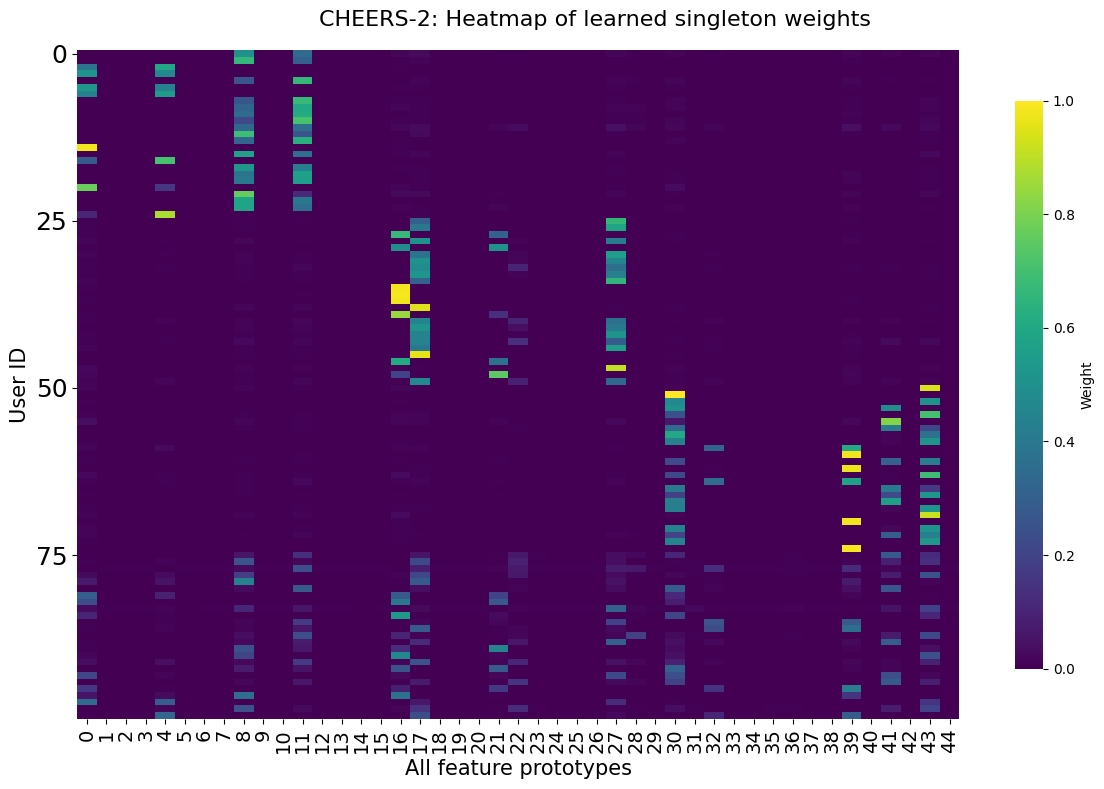

In [8]:
user_representations = model.preference_model.coefficients(model.user_encoder.embedding.weight)
plot_user_weights(user_representations, user_ids=None) #TODO add [0] if loaded model is CHEERS-2 (Choquet2AdditivePreference)


* Plot t-SNE embeddings

(<Figure size 800x600 with 1 Axes>, <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

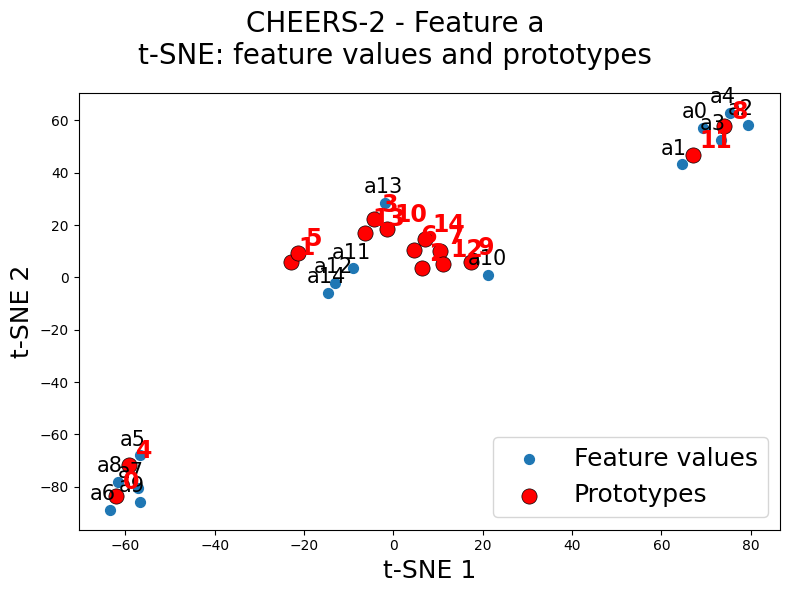

In [9]:
feature_name = 'a'

feature_values_embeddings = model.item_encoder.feature_embeddings[feature_name].embedding.weight.data
feature_values_embeddings = feature_values_embeddings / feature_values_embeddings.norm(dim=1, keepdim=True)  # normalize for cosine similarity

prototypes_embeddings = model.criteria_encoder.prototypes[feature_name].data
prototypes_embeddings = prototypes_embeddings / prototypes_embeddings.norm(dim=1, keepdim=True)

plot_embeddings_tsne(prototypes_embeddings, feature_values_embeddings, feature_name=feature_name, metric='euclidean')

* Plot cosine similarity of feature values

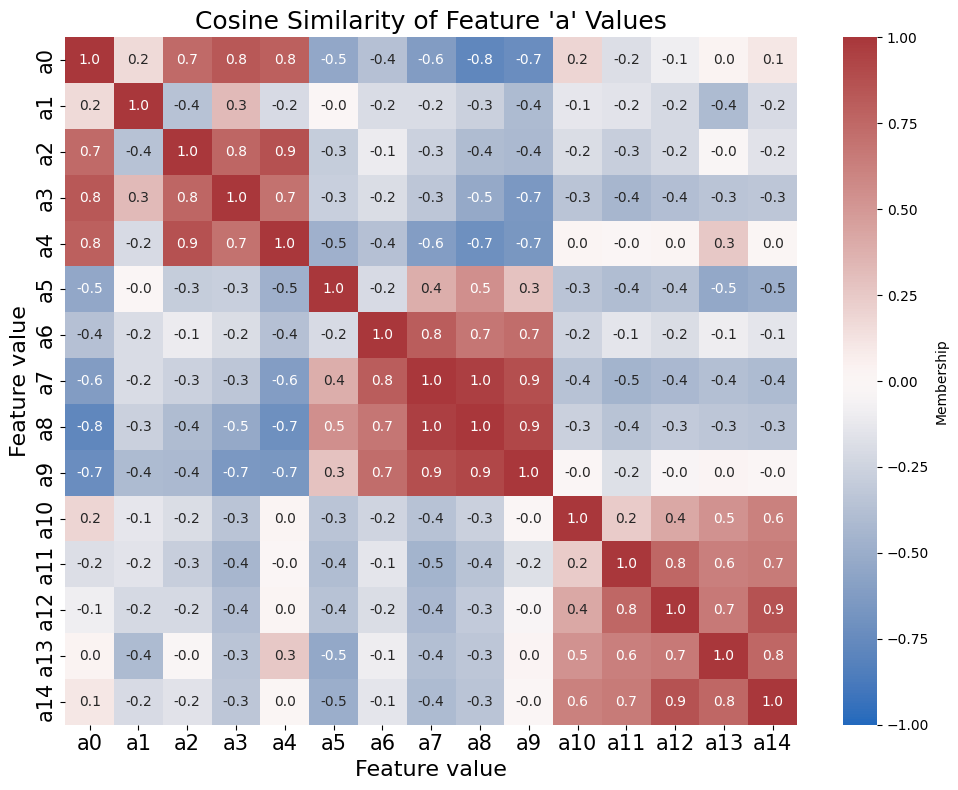

In [10]:
feature_name = 'a' 
feature_values_embeddings = model.item_encoder.feature_embeddings[feature_name].embedding.weight.data
feature_values_embeddings = feature_values_embeddings / feature_values_embeddings.norm(dim=1, keepdim=True)  # normalize for cosine similarity
feature_values_embeddings = feature_values_embeddings@feature_values_embeddings.T
feature_values_embeddings = feature_values_embeddings.detach().cpu()
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    feature_values_embeddings,
    ax=ax,
    vmin=-1, vmax=1,
    cmap="vlag",
    annot=True, fmt=".1f",
    xticklabels=[f"{feature_name}{i}" for i in range(len(feature_values_embeddings))],
    yticklabels=[f"{feature_name}{i}" for i in range(len(feature_values_embeddings))],
    cbar_kws={"label": "Membership"}, # bigger size

)

ax.set_xlabel("Feature value", fontsize=16)
ax.set_ylabel("Feature value", fontsize=16)
ax.set_title(f"Cosine Similarity of Feature '{feature_name}' Values", fontsize=18)
ax.tick_params(axis="x", labelsize=15)
ax.tick_params(axis="y", labelsize=15)
fig.tight_layout()
plt.show()